# sEMG gesture classifier: preprocessing + five models compared

This notebook trains models that look at 250 ms of armband signal and say which of 6 hand gestures is being made. It trains five models on exactly the same data and compares them: **RNN, LSTM, CNN, CNN-RNN and CNN-LSTM**.

It follows the plan in `PrePro.ipynb`:

1. Settings, loading and a first look at the data
2. Cleaning the signal: zero-centering, notch filter, band-pass filter
3. Cutting the signal into overlapping windows and splitting the data
4. Normalisation
5. The five models: training, testing and comparing them

**Data:** 36 subjects (folders `01` to `36`), 2 recordings each, 8 armband channels, sampled at 200 Hz.

**How to run:** keep this notebook in the same folder as the `Data` folder, then run the cells from top to bottom. Every step prints the shape of the data it produces, so you can follow along.

Every model is built for real-time use later. None of them ever looks at the future, only the past. Step 9 checks this.

### Step 0: install the libraries (only needed once)

Remove the `#` and run this cell if any import in Step 1 fails.

In [126]:
# pip install torch scipy scikit-learn pandas matplotlib seaborn


## Step 1: imports and settings

All the numbers you might want to change live in this one cell.

In [127]:
import time
from pathlib import Path

import Preprocessing as pp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import iirnotch, butter, lfilter, sosfilt, welch
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

import torch
import torch.nn as nn
import torch.nn.functional as F

## Step 1: settings

### What it does
This cell defines every adjustable number in the notebook as a named constant. It adds no data and does no processing. Later steps read these names (`WINDOW_SIZE`, `STEP`, `BATCH_SIZE`, ...) instead of containing their own numbers. The last three lines fix the random seeds and print the resulting window size.

### The settings and how much each one matters

| Setting | What it controls | Importance |
|---|---|---|
| `DATA_FOLDER` | Where Step 2 looks for the recordings (`Data/01/01.txt` ...). | **Critical.** A wrong path means no files load and nothing after it works. |
| `CHANNELS` | The eight electrode column names, `V1` to `V8`, built with a loop so they match the file headers. | **Critical.** A name that does not match the header stops loading. |
| `GESTURES` | Maps each gesture name in the files to a class number from 1 to 7. | **Critical.** Step 5 keeps only labels listed here and turns them into the `y` the model learns. A misspelt name makes that gesture silently disappear from the dataset. |
| `SAMPLE_RATE` | How many readings per second the signal contains. It converts milliseconds into samples and tells every filter what "1 Hz" means. | **Very high.** Every filter cut-off and the window's real length depend on it. It is an assumption, not a measurement (see below). |
| `NOTCH_HZ` | The frequency the notch filter removes, normally 50 Hz mains hum. `0` switches it off. | **Low here.** A 50 Hz notch cannot exist at this sampling rate (the limit is 30 Hz), so it is correctly off. |
| `LOW_HZ`, `HIGH_HZ` | The pass band of the band-pass filter in Step 4: the slowest and fastest changes that are kept. | **High.** They decide what part of the signal the models ever see. `HIGH_HZ` must stay below `SAMPLE_RATE / 2`. |
| `WINDOW_MS`, `WINDOW_SIZE` | How much signal forms one example. `WINDOW_SIZE` is derived: `SAMPLE_RATE * WINDOW_MS // 1000`, a whole number of samples. | **High.** It sets the model's input shape (`[60, 8]`), how much context each decision has, and how many windows exist. |
| `STEP` | How many samples the window slides each time. | **High.** A smaller step gives more examples, but neighbouring windows share more data. With 60 and 4, they share 56 of 60 samples (93%). This overlap is why Step 6 must split along time and not at random. |
| `BATCH_SIZE` | Windows the model sees before each weight update. | Medium. Affects training speed and noise, rarely the final result. |
| `EPOCHS` | Passes over the training set. | Medium. Too few under-trains, too many over-fits. |
| `LEARNING_RATE` | Size of each weight update. | Medium to high. A bad value stops training or makes the loss jump around. |
| `SEED` | Starting point for every random number generator. | **Important for trust.** Weight initialisation, shuffling and the class-balancing draw are random. A fixed seed means a change in score comes from something you changed. |

### Why `SAMPLE_RATE` deserves the most attention
The notebook assumes 60 readings per second for every file, but the files do not share one rate (rows divided by recording duration):

- about 24–32 Hz for fist, flexion, extension, radial and ulnar
- about 51–53 Hz for rest and table

So the same 60-sample window covers about 1.1 s of real time in the rest and table recordings and up to 2.5 s in the others, as the chart shows. The filter cut-offs in Hz are also only exact if the rate is right. Changing `SAMPLE_RATE` changes the window length and the filters, and therefore every result.

### Why the settings live in one place
- **Consistency:** the window size is defined once, so two steps cannot use different sizes.
- **Experiments:** trying a 500 ms window means editing `WINDOW_MS` and re-running.
- **Reporting:** the cell records the exact configuration behind any result.

In [128]:
# ---------- data ----------
DATA_FOLDER = Path("Data")          # the folder that holds all data
CHANNELS = [f"V{i+1}" for i in range(8)]
GESTURES = {"fist": 1, "flexion": 2, "extension": 3, "radial": 4, "ulnar": 5, "rest": 6, "table": 7}
GESTURE_NAMES = list(GESTURES.values())

# ---------- signal ----------
SAMPLE_RATE = 40                  # Hz: the armband sends 60 readings per second
NOTCH_HZ = 0                       
LOW_HZ = 1                         
HIGH_HZ = 8                       

# ---------- windows ----------
WINDOW_MS = 300                                 
WINDOW_SIZE = SAMPLE_RATE * WINDOW_MS // 1000  # 18000 / 1000 = 18 windows per second
STEP = 4                                        

# ---------- training ----------
BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 0.001
print("window size:", WINDOW_SIZE, "samples")

window size: 12 samples


## Step 2: load the data

Each file is a table with columns `time, channel1 ... channel8, class`.

One quirk: the file has a row about every 1 ms, but the armband only sends a new reading every 5 ms. So most rows are copies of the row before. `load_file` keeps one row per 5 ms slot, which gives an even 200 readings per second.

`class` is the gesture being made: 1 to 6 are the gestures, 0 means "unmarked" (the pauses between gestures). Subjects 11 and 30 also did a 7th gesture that nobody else did, so it is left out later.

In [129]:
def load_file(path):
    """Read one recording. Returns the signal [samples, 8] and the labels [samples]."""
    table = pd.read_csv(path)
    table = table.dropna()                          # one file has an empty last row

    print(table.head())
    # Put each row into a 5 ms slot and keep the last row in each slot
    # slot_ms = 1000 // SAMPLE_RATE                   # 5 ms
    
    # table["slot"] = (table["Time"] - table["Time"].iloc[0]) // slot_ms
    # table = table.groupby("slot").last()

    # If a slot is empty, copy the reading from the slot before it
    table = table.reindex(range(table.index.max() + 1)).ffill()

    signal = table[CHANNELS].to_numpy(dtype=np.float32)
    labels = table["Gesture"].to_numpy()
    return signal, labels

In [130]:
recordings = []

print("Working directory:", Path.cwd())
print("Data folder exists:", DATA_FOLDER.exists())
print("Data folder path:", DATA_FOLDER.resolve())

for path in sorted(DATA_FOLDER.glob("*/*.txt")):
    print("loading", path)
    signal, labels = load_file(path)
    recordings.append({
        "subject": path.parent.name,               # "01" ... "36"
        "session": int(path.stem[0]),   # 1 or 2 (first or second recording)
        "signal": signal,
        "labels": labels,
    })


print(len(recordings), "recordings loaded")
print("first recording signal shape:", recordings[0]["signal"].shape, "(samples, channels)")
print("first recording length:", len(recordings[0]["labels"]) / SAMPLE_RATE, "seconds")

Working directory: d:\Study\SC dir\Capstone Project\New folder\Capstone\Capstone\Process
Data folder exists: True
Data folder path: D:\Study\SC dir\Capstone Project\New folder\Capstone\Capstone\Process\Data
loading Data\01\01.txt
    Time    V1    V2    V3    V4    V5    V6    V7    V8 Gesture
0  175.0  2045  2063  2061  2054  2032  2053  2047  2075    fist
1  180.0  2051  2058  2041  2027  2047  2048  2043  2064    fist
2  185.0  2050  2044  2046  2031  2036  2038  2039  2058    fist
3  195.0  2044  2054  2048  2058  2050  2061  2043  2096    fist
4  205.0  2048  2034  2029  2030  2047  2039  2038  2052    fist
loading Data\02\02.txt
    Time    V1    V2    V3    V4    V5    V6    V7    V8  Gesture
0  158.0  2046  2059  2025  2047  2028  2043  2039  2053  flexion
1  163.0  2045  2058  2026  2047  2029  2044  2040  2053  flexion
2  188.0  2047  2060  2021  2056  2040  2053  2050  2046  flexion
3  193.0  2048  2060  2023  2058  2039  2054  2050  2046  flexion
4  233.0  2046  2054  2072 

In [131]:
all_recordings = []

all_signals = np.concatenate([r["signal"] for r in recordings], axis=0)
all_labels = np.concatenate([r["labels"] for r in recordings], axis=0)

print("Combined signal shape:", all_signals.shape)
print("Combined labels shape:", all_labels.shape)

Combined signal shape: (41709, 8)
Combined labels shape: (41709,)


## Step 3: look at the data

Before changing anything, look at one recording. Each coloured band is one gesture. The grey gaps are the unmarked pauses (class 0).

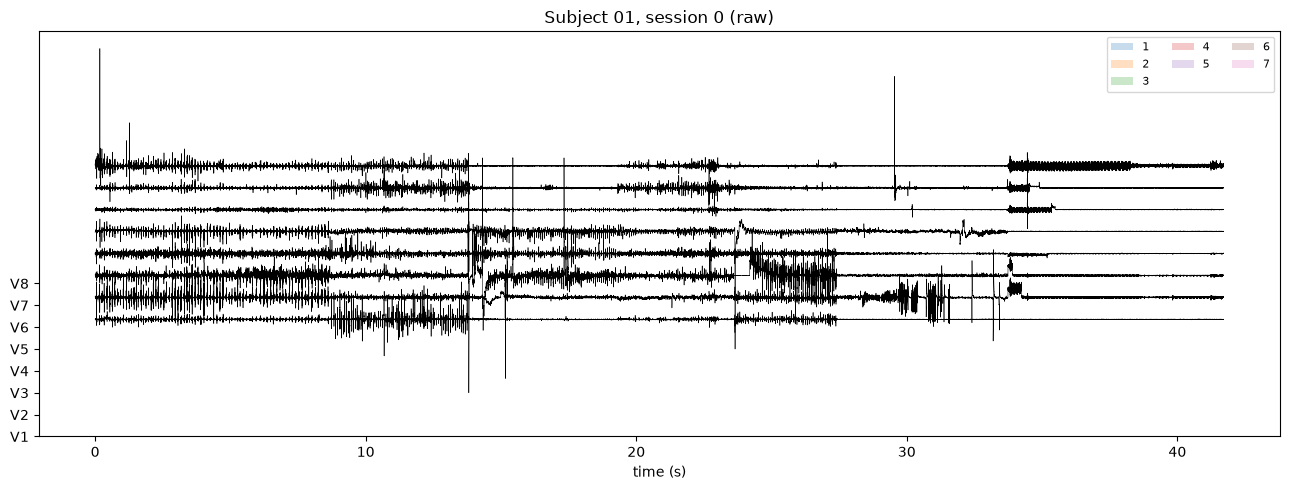

In [132]:
def plot_recording(signal, labels, title):
    seconds = np.arange(len(labels)) / 1000
    spacing = 8 * np.std(signal)                      # gap between the 8 lines

    plt.figure(figsize=(13, 5))
    for ch in range(8):
        plt.plot(seconds, signal[:, ch] + ch * spacing, linewidth=0.4, color="black")
    for number, name in GESTURES.items():
        plt.fill_between(seconds, -spacing, 8 * spacing, where=(labels == name), alpha=0.25, label=name)
    plt.yticks([ch * spacing for ch in range(8)], CHANNELS)
    plt.xlabel("time (s)")
    plt.title(title)
    plt.legend(loc="upper right", ncol=3, fontsize=8)
    plt.tight_layout()
    plt.show()


first = recordings[0]
plot_recording(all_signals, all_labels, f"Subject {first['subject']}, session {first['session']} (raw)")

In [133]:
def remove_outliers_mask(data):
    mean = data[CHANNELS].mean()
    std = data[CHANNELS].std()

    mask = ((data[CHANNELS] - mean).abs() <= 3 * std).all(axis=1)

    return data.loc[mask].copy()

In [ ]:
df = pd.DataFrame(all_signals, columns=CHANNELS)
df["Gestures"] = all_labels


print("Original data shape:", df.shape)

reduced_df = remove_outliers_mask(df)

reduced_signals = reduced_df[CHANNELS].to_numpy()
reduced_labels = reduced_df["Gestures"].to_numpy()

plot_recording(reduced_signals, reduced_labels, "Signal after removing outliers")

TypeError: Cannot perform reduction 'mean' with string dtype

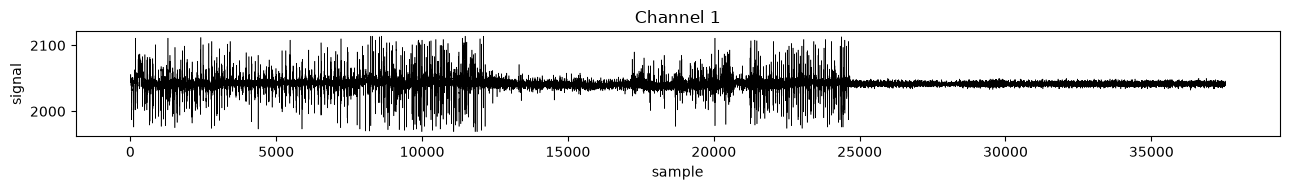

Channel 1 mean: 2041.7388 std: 9.600418


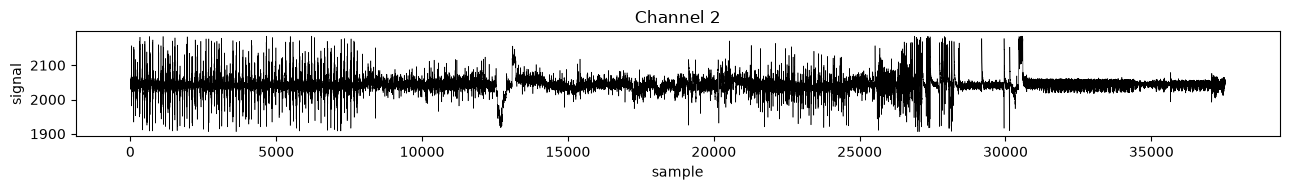

Channel 2 mean: 2044.1224 std: 25.800919


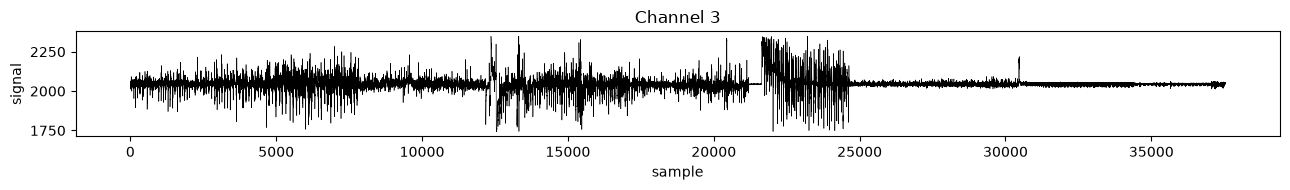

Channel 3 mean: 2044.1431 std: 45.271896


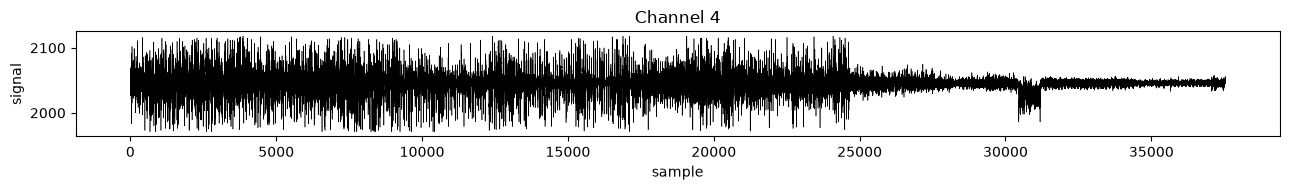

Channel 4 mean: 2044.8495 std: 16.814512


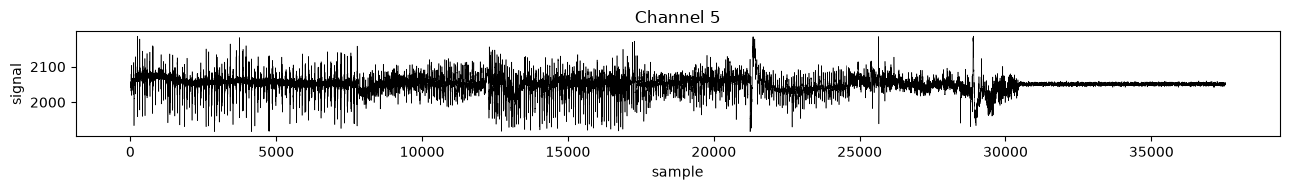

Channel 5 mean: 2051.4294 std: 22.60966


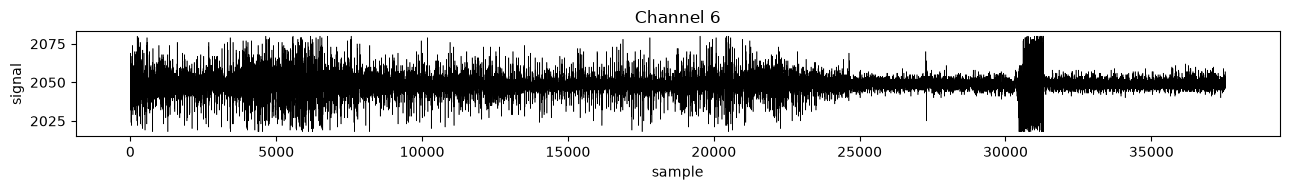

Channel 6 mean: 2048.8044 std: 6.647916


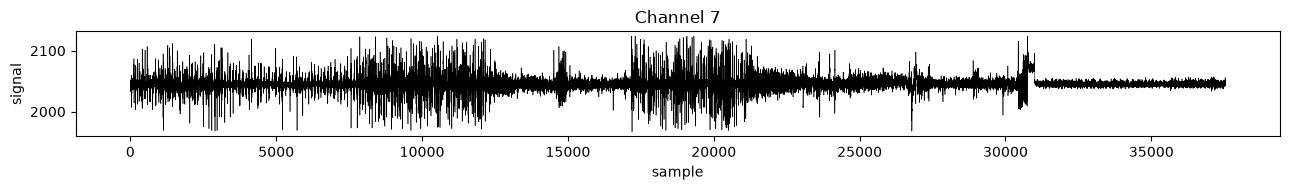

Channel 7 mean: 2045.617 std: 12.4359455


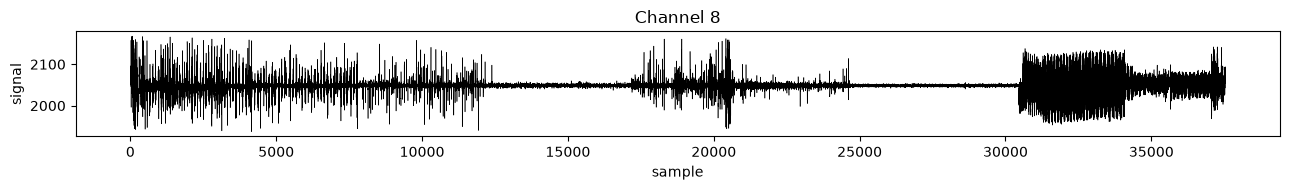

Channel 8 mean: 2048.4646 std: 20.417656


In [ ]:
for i in range(8):
    plt.figure(figsize=(13, 2))
    plt.plot(reduced_signals[:, i], linewidth=0.4, color="black")
    plt.title(f"Channel {i+1}")
    plt.xlabel("sample")
    plt.ylabel("signal")
    plt.tight_layout()
    plt.show()
    print("Channel", i+1, "mean:", reduced_signals[:, i].mean(), "std:", reduced_signals[:, i].std())

## Step 4: clean the signal

Three cleaning steps, the same ones planned in `PrePro.ipynb`:

1. **Zero-centering:** subtract each channel's average, so a relaxed muscle sits at zero.
2. **Notch filter at 50 Hz:** removes hum from wall power.
3. **Band-pass filter, 10 to 90 Hz:** removes slow bumps from the band rubbing on the skin, and very fast static. Muscle activity lives in between. The guide suggests 10 to 150 Hz, but at 200 Hz sampling nothing above 100 Hz can exist in the data, so 90 Hz is used.

The filters use `lfilter`/`sosfilt`, which only look at past samples. That is what a live system can do. (`filtfilt` also looks at future samples, so it is not used.)

In [136]:
# Design the two filters once
#notch_b, notch_a = iirnotch(NOTCH_HZ, Q=30, fs=SAMPLE_RATE)
#bandpass = butter(4, [LOW_HZ, HIGH_HZ], btype="bandpass", fs=SAMPLE_RATE, output="sos")
#
#
#
#def clean(raw):
#    """Zero-centre, notch-filter and band-pass-filter one recording [samples, 8]."""
#    x = raw - raw.mean(axis=0)                     # 1) zero-centering
#    x = lfilter(notch_b, notch_a, x, axis=0)       # 2) notch filter
#    x = sosfilt(bandpass, x, axis=0)               # 3) band-pass filter
#    return x.astype(np.float32)
#
#cleaned_signals = clean(reduced_signals)
#
#print("cleaned", len(cleaned_signals), "recordings; shape stays", cleaned_signals.shape)
data = pp.preprocess_pipeline(df, SAMPLE_RATE, NOTCH_HZ, LOW_HZ, HIGH_HZ)



TypeError: Cannot perform reduction 'mean' with string dtype

Compare one channel before and after cleaning, in time (left) and by frequency (right). On the right, the cleaned line should drop away below 10 Hz and above 90 Hz.

In [ ]:
raw = reduced_signals[:, 0]
cleaned = cleaned_signals[:, 0]
seconds = np.arange(len(raw)) / SAMPLE_RATE
show = (seconds > 5) & (seconds < 10)              # a 5-second stretch


fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].plot(seconds[show], raw[show], linewidth=0.6, label="raw")
ax[0].plot(seconds[show], cleaned[show], linewidth=0.6, label="cleaned")
ax[0].set_xlabel("time (s)"); ax[0].set_title("Channel 1 over time"); ax[0].legend()


f_raw, p_raw = welch(raw, fs=SAMPLE_RATE, nperseg=256)
f_cln, p_cln = welch(cleaned, fs=SAMPLE_RATE, nperseg=256)
ax[1].semilogy(f_raw, p_raw, label="raw")
ax[1].semilogy(f_cln, p_cln, label="cleaned")
ax[1].axvline(NOTCH_HZ, color="grey", linestyle="--", linewidth=0.8)
ax[1].set_xlabel("frequency (Hz)"); ax[1].set_title("Channel 1 by frequency"); ax[1].legend()
plt.tight_layout()
plt.show()

KeyboardInterrupt: 

## Step 5: cut the signal into windows

### Description

The models don't read a whole recording at once. They classify short **windows**: each one is
`WINDOW_SIZE` samples (50 samples = 250 ms) of all 8 channels. A new window starts every `STEP`
samples, so neighbouring windows overlap and each recording yields many examples.

A window is kept only if every sample in it has the same gesture label. A window that covers two
labels has no single correct answer, so it is skipped, as is any window whose label is not one of
the gestures in `GESTURES`.

Each kept window is also tagged with **where it starts** and **which recording it came from**.
Step 6 needs both, because it cuts every recording along time.

![Sliding windows](Images/sliding_windows.png)

### Process

**1. Slide the window along the signal (`make_windows`).**
For every start position, moving `STEP` samples at a time:
- take the labels of the next `WINDOW_SIZE` samples;
- skip the window if its first label is not a gesture in `GESTURES` (for example a pause);
- skip it if the label changes anywhere inside it;
- otherwise keep the window, its gesture and its start position.

**2. Turn the lists into arrays.**
`X` holds the windows, shape `[windows, WINDOW_SIZE, 8]`. `y` holds each gesture's number
minus 1, so labels start at 0 as PyTorch expects. `win_start` holds where each window begins
in the long array of all recordings.

**3. Find which recording every sample came from.** 
The outlier step deleted some rows, so a position in `cleaned_signals` no longer matches the
original data. But `reduced_df.index` still holds each kept row's **original** row number.
`file_ends` lists where each original recording ends (the running total of their lengths), and
`np.searchsorted(file_ends, index, side="right")` turns each original row number into a file number.

![Tracing rows back to their recording](Images/window_file_lookup.png) 

**4. Find which recording every window came from.**
A window takes the file of its first sample: `file_of_window = file_of_sample[win_start]`.
This is safe because a window never spans two files: neighbouring files hold different
gestures, so the label check in step 1 already drops any window that would cross from one file to the next.

**5. Print a summary.**
The shape of `X` and the number of windows per recording, to check that every file contributed.

### Notes

- **Windows across removed rows.** Where outlier rows were deleted, the samples on either side
  now sit next to each other, so a window there can join two moments that were not consecutive
  in time. If outliers were rare this has little effect; the check below counts and removes such windows.
- **Original row numbers.** Step 3 only works if the combined table was built with one running
  index across all recordings (`0, 1, 2, …` to the end), for example with `pd.concat(..., ignore_index=True)`.
  If each file's index restarted at 0, the file lookup would be wrong.

In [ ]:
def make_windows(x, labels):
    """Slide a window along the signal.

    x       : signal, shape [samples, 8] (all recordings stored end to end)
    labels  : gesture label of every sample, same length as x

    Returns the windows, their labels, and each window's start position.
    """
    windows, window_labels, starts = [], [], []    # results are collected here

    # Try a window at every STEP-th position. The last start is
    # len(x) - WINDOW_SIZE, so the final window still fits inside the signal.
    for start in range(0, len(x) - WINDOW_SIZE + 1, STEP):
        end = start + WINDOW_SIZE                  # one past the window's last sample
        chunk_labels = labels[start:end]           # the label of every sample in this window
        gesture = chunk_labels[0]                  # the label the window starts with

        # Rule 1: the window must start on a gesture we classify
        if gesture not in GESTURES:                # skip pauses (0) and unused gestures
            continue

        # Rule 2: every sample must have that same label. This also drops
        # windows that run from one file into the next, because neighbouring
        # files hold different gestures.
        if np.any(chunk_labels != gesture):        # skip windows that cross into another label
            continue

        # The window passed both rules: keep it
        windows.append(x[start:end])               # the signal itself, shape [WINDOW_SIZE, 8]
        window_labels.append(gesture)              # its gesture
        starts.append(start)                       # where it begins, needed later for the time-based split
    return windows, window_labels, starts

In [ ]:
# Cut the cleaned signal into windows (see make_windows above)
windows, labels, starts = make_windows(cleaned_signals, reduced_labels)

# Turn the Python lists into NumPy arrays the model can use
X = np.array(windows, dtype=np.float32)               # [windows, WINDOW_SIZE, 8]
y = np.array([GESTURES[label] for label in labels]) - 1   # gesture name -> number, minus 1 so labels start at 0
win_start = np.array(starts)                          # where each window begins in the long array


# Which recording does each window come from?
# All recordings sit end to end in one long array. The outlier step deleted
# some rows, so positions in that array no longer match the original files.
# reduced_df.index still holds each kept row's ORIGINAL row number, so that
# number is used to look up the file.
file_names     = [r["subject"] for r in recordings]                 # folder name of each recording ("01" ... "07")
file_ends      = np.cumsum([len(r["signal"]) for r in recordings])  # original row where each recording ends, e.g. [13133, 26100, ...]

# For every kept row: find the first file whose end lies after its original row number.
# side="right" makes a row that sits exactly on a boundary belong to the next file.
file_of_sample = np.searchsorted(file_ends, reduced_df.index.to_numpy(), side="right")

# A window belongs to the file of its first sample.
# (Windows never span two files: neighbouring files hold different gestures,
#  so make_windows already dropped any window crossing a file boundary.)
file_of_window = file_of_sample[win_start]


# Quick checks: the shape of X, and that every recording produced windows
print("X:", X.shape, "(windows, time steps, channels)")
print("windows per recording:", dict(zip(file_names, np.bincount(file_of_window))))

X: (9355, 18, 8) (windows, time steps, channels)
windows per recording: {'01': np.int64(1954), '02': np.int64(1084), '03': np.int64(1232), '04': np.int64(1015), '05': np.int64(857), '06': np.int64(1445), '07': np.int64(1768)}


## Step 6: split into train, validation and test

### Description

This dataset has a simple structure: **each gesture is one continuous recording**.
Folder `01` contains nothing but `fist`, `02` nothing but `flexion`, and so on up to `07`.
So the folders are gestures, not people, and `session` is `0` everywhere.

That rules out the usual ways of splitting:

| Split | Why it can't be used here |
|---|---|
| By subject | There is only one person. |
| By session | There is only one session. |
| By file | Each file is one gesture, so whole gestures would end up only in test and never be trained on. |
| By repetition | Each gesture was recorded once, as one long hold. |

The option that is left is a **chronological cut inside each file**. The first 60% of every
recording is used for training, the next 20% for validation and the last 20% for testing.
Because every file is cut the same way, every gesture appears in all three sets.

![Split by file vs cutting inside each file](Images/split_by_file_vs_chrono.png) 

Neighbouring windows overlap, because each window starts only `STEP` samples after the last.
A window that crosses a cut would contain samples from two sets, so those windows are dropped.
No raw sample is ever shared between training, validation and test, and the check below proves it.

### Process

**1. Relabel the gestures as 0, 1, 2, … with no gaps.**
The loss function needs labels numbered from 0 with no gaps. `np.unique` lists the labels
that actually occur, and `np.searchsorted` replaces each label with its position in that list.
`GESTURE_NAMES` is rebuilt in the same order, and `N_CLASSES` becomes the number of gestures present.

**2. Find where each window sits inside its own recording.**
All recordings are stored end to end in one long array, so `win_start` is a position in that
long array. `file_start` is where each recording begins, and `file_len` is how many samples it has.
Subtracting gives `start`, the window's position inside its own file. `end` is `start + WINDOW_SIZE`.

![Window position inside its file](Images/window_local_position.png) 

**3. Cut every recording at 60% and 80% of its length.**
The two cut points are worked out separately for every file. A window is assigned to a set only
if it fits completely inside that section:

- train: the window ends at or before the 60% cut (`end <= cut1`)
- validation: it starts at or after the 60% cut and ends at or before the 80% cut
- test: it starts at or after the 80% cut (`start >= cut2`)
- any other window crosses a cut and is dropped

![Which split each window goes to](Images/window_cut_rules.png) 

**4. Report and check.**
A table counts, for every file, how many windows went to each set and how many were dropped.
A final check marks every raw sample each set uses and asserts that no sample is used by
two sets. It also asserts that every gesture has test windows.

### Limitations

- **Gesture and recording are the same thing.** Each gesture comes from its own file, so the
  model could partly learn the conditions of that recording (electrode contact, signal level)
  instead of the gesture itself. Training and test windows come from the same files, so the
  test score is likely optimistic. A fresh recording session, with the armband taken off and
  put back on, is needed to measure real-world accuracy (ML-N-03).
- **Test data comes from the end of each recording.** This is a fair test of "later in time",
  but fatigue or electrode drift near the end may make it slightly harder than the start.
- **Windows either side of a cut are next to each other in time.** They share no samples,
  but they are very similar.

In [ ]:
# ---------- split settings ----------
SPLIT_BY = "chrono"            # split each recording along time: start = train, middle = val, end = test
VAL_FRAC, TEST_FRAC = 0.2, 0.2 # 20% validation + 20% test, so the first 60% of each recording is training


''' 1. Relabel the gestures present as 0, 1, 2, ... with no gaps
#    CrossEntropyLoss needs labels 0 .. N_CLASSES-1. If a gesture is missing
#    from this data (e.g. labels 0, 1, 2, 4, 5), the gap has to be closed.
'''
by_number     = {number - 1: name for name, number in GESTURES.items()}  # 0-based label -> gesture name
present       = np.unique(y)                       # labels that actually occur, sorted, e.g. [0 1 2 4 5]
y             = np.searchsorted(present, y)        # each label -> its position in `present` (4 -> 3, 5 -> 4)
GESTURE_NAMES = [by_number[p] for p in present]    # gesture names in the new label order
N_CLASSES     = len(present)                       # size of the model's output layer


''' 2. Where does each window sit inside its own recording?
    All recordings are stored end to end in one long array, so win_start is a position in that long array. Subtracting where the window's recording 
    begins gives its position inside that recording. (file_of_sample must be sorted, i.e. files stored one after another.)
'''
n_files    = len(file_names)
file_start = np.searchsorted(file_of_sample, np.arange(n_files))   # where each file's first kept sample sits in the long array
file_len   = np.bincount(file_of_sample, minlength=n_files)        # number of kept samples in each file
start = win_start - file_start[file_of_window]     # window start, counted from the beginning of its own file
end   = start + WINDOW_SIZE                         # one past the window's last sample


# 3. Cut every recording at 60% and 80% of its length. A window must fit
#    entirely inside one section; windows that straddle a cut are dropped.
#    The cut points are computed per file, then looked up for each window.
cut1 = (file_len * (1 - VAL_FRAC - TEST_FRAC)).astype(int)[file_of_window]   # 60% point of this window's file
cut2 = (file_len * (1 - TEST_FRAC)).astype(int)[file_of_window]              # 80% point of this window's file

is_train = end <= cut1                         # whole window before the 60% cut
is_val   = (start >= cut1) & (end <= cut2)     # whole window between the two cuts
is_test  = start >= cut2                       # whole window after the 80% cut
                                               # any other window crosses a cut and is left out

X_train, y_train = X[is_train], y[is_train]
X_val,   y_val   = X[is_val],   y[is_val]
X_test,  y_test  = X[is_test],  y[is_test]
test_file = np.array(file_names)[file_of_window[is_test]]   # recording each test window came from (for per-file results)

In [ ]:
# 4. Report: for every recording and gesture, how many windows went to each split
summary = pd.DataFrame({"file": np.array(file_names)[file_of_window],   # one row per window
                        "gesture": np.array(GESTURE_NAMES)[y],
                        "train": is_train, "val": is_val, "test": is_test})

summary = summary.groupby(["file", "gesture"]).agg(
            windows=("train", "size"),   # all windows of this gesture in this file
            train=("train", "sum"),      # True counts as 1, so the sum is the number in train
            val=("val", "sum"),
            test=("test", "sum"))

summary["dropped"] = summary["windows"] - summary[["train", "val", "test"]].sum(axis=1)  # lost because they crossed a cut
print(summary, "\n")


# 5. Check: no raw sample may be used by two different splits
#    One row per split, one column per raw sample. Each split marks every sample
#    its windows touch. Overlap inside one split is fine; overlap between splits
#    would put test signal into training (a leak).
used = np.zeros((3, len(cleaned_signals)), dtype=int)   # rows: train, val, test
for k, mask in enumerate((is_train, is_val, is_test)):
    for s in win_start[mask]:
        used[k, s:s + WINDOW_SIZE] = 1                   # this split uses samples s .. s+WINDOW_SIZE-1
shared = int((used.sum(axis=0) > 1).sum())               # samples used by two or three splits
print(f"samples shared between splits: {shared}   (must be 0)")
assert shared == 0, "split leak: windows from different splits share raw samples"

#    Every gesture needs at least one test window, or its accuracy can't be measured
for c in range(N_CLASSES):
    assert (y_test == c).any(), f"{GESTURE_NAMES[c]} has no test windows"

                windows  train  val  test  dropped
file gesture                                      
01   fist          1954   1171  387   388        8
02   flexion       1084    649  213   213        9
03   extension     1232    737  242   243       10
04   radial        1015    607  200   200        8
05   ulnar          857    513  168   168        8
06   rest          1445    865  286   286        8
07   table         1768   1059  350   350        9 

samples shared between splits: 0   (must be 0)


## Step 7: normalise each channel (and even out the class sizes)

The recordings are different lengths, so some gestures contribute far more windows than
others. `BALANCE_TRAIN` caps every training class at the median count. Validation and test
keep their natural balance — rebalancing those would make the reported accuracy meaningless.

Normalisation statistics come from the **training windows only**, then the same two numbers
scale validation and test. Both are saved with the model in Step 12, because live data has
to be scaled identically.


### Justification

**The problem it solves**
Training rewards the model for getting as many windows right as possible. If one gesture dominates the training data, like “rest” in the example above with more than twice as many windows as the others, the model learns that guessing “rest” is usually a safe bet. It then over-predicts that gesture and under-predicts the rare ones. Accuracy can still look fine, because the common gesture carries the score, while the rare gestures do badly. Your macro F1 score, which counts every gesture equally, would expose this.

**What capping does** 
It trims every gesture down to at most the median count, here 410. The over-represented gestures lose their extra windows, and gestures already below the cap keep all of theirs. Each gesture then has roughly the same say during training.

**What it costs** 
It throws data away: in the example, about 530 windows. With a small dataset that’s a real loss. That’s why the loss-weighting alternative I gave you is often preferred: it keeps every window but makes mistakes on rare gestures count more.

In [ ]:
BALANCE_TRAIN = True   # give every gesture at most the median number of training windows

DATA_SEED = 0
if BALANCE_TRAIN:
    counts = np.bincount(y_train, minlength=N_CLASSES)   # training windows per gesture
    cap = int(np.median(counts[counts > 0]))             # the middle count becomes the limit
    rng = np.random.default_rng(DATA_SEED)

    keep = []
    for c in range(N_CLASSES):
        idx = np.flatnonzero(y_train == c)               # positions of this gesture's windows
        if len(idx) > cap:
            idx = rng.choice(idx, cap, replace=False)    # too many: keep a random `cap` of them
        keep.extend(idx)
    keep = np.sort(keep)                                 # back in the original order

    X_train, y_train = X_train[keep], y_train[keep]

    print(f"capping each training class at {cap} windows")
    after = np.bincount(y_train, minlength=N_CLASSES)
    for name, b, a in zip(GESTURE_NAMES, counts, after):
        print(f"  {name:16s} {b:5d} -> {a:5d}")


# Normalise each channel using the training windows only, then apply to all three sets
channel_mean = X_train.mean(axis=(0, 1))          # one value per channel
channel_std  = X_train.std(axis=(0, 1)) + 1e-8    # the tiny number avoids dividing by 0

def normalise(x):
    return (x - channel_mean) / channel_std

X_train, X_val, X_test = normalise(X_train), normalise(X_val), normalise(X_test)
print(f"after normalising: train mean {X_train.mean():+.3f}, std {X_train.std():.3f}")

capping each training class at 737 windows
  fist              1171 ->   737
  flexion            649 ->   649
  extension          737 ->   737
  radial             607 ->   607
  ulnar              513 ->   513
  rest               865 ->   737
  table             1059 ->   737
after normalising: train mean -0.000, std 1.000


## Step 8: put the data into PyTorch

In [ ]:
train_data = torch.utils.data.TensorDataset(torch.tensor(X_train), torch.tensor(y_train))
val_data   = torch.utils.data.TensorDataset(torch.tensor(X_val),   torch.tensor(y_val))
test_data  = torch.utils.data.TensorDataset(torch.tensor(X_test),  torch.tensor(y_test))

train_loader = torch.utils.data.DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = torch.utils.data.DataLoader(val_data,   batch_size=BATCH_SIZE)
test_loader  = torch.utils.data.DataLoader(test_data,  batch_size=BATCH_SIZE)

batch_x, batch_y = next(iter(train_loader))
print("one batch of windows:", tuple(batch_x.shape), "(batch, time steps, channels)")
print("one batch of labels: ", tuple(batch_y.shape),
      f"values {int(batch_y.min())}..{int(batch_y.max())}")
print(f"\n>>> Step 9 needs n_classes={N_CLASSES}. In the `build_model` cell change")
print(f">>>     return MODEL_CLASSES[name]()")
print(f">>> to  return MODEL_CLASSES[name](n_classes=N_CLASSES)")

one batch of windows:

 (64, 18, 8) (batch, time steps, channels)
one batch of labels:  (64,) values 0..6

>>> Step 9 needs n_classes=7. In the `build_model` cell change
>>>     return MODEL_CLASSES[name]()
>>> to  return MODEL_CLASSES[name](n_classes=N_CLASSES)


## Step 9: the five models

All five models take the same input, a window of shape `[batch, 60, 8]` (`WINDOW_SIZE` samples of all 8 channels), and give one score for each of the 7 gestures (`N_CLASSES`). They differ in how they read the window:

| Model | How it reads the window |
|---|---|
| **RNN** | Reads the 60 raw samples in order and keeps a simple memory. |
| **LSTM** | Same, but with a better memory (gates and a cell state) that fades less. |
| **CNN** | Slides small filters over the window to find patterns. No memory, just filters. |
| **CNN-RNN** | A CNN finds short patterns first, then an RNN reads those patterns in order. |
| **CNN-LSTM** | The same CNN first, then an LSTM. |

Every model has two functions:

- `all_steps(x)` gives the model's output at every time step.
- `forward(x)` keeps only the last step and turns it into the gesture scores.

**Causal padding:** a convolution with `kernel_size=5` needs 4 extra samples at the edge. They are always added on the **left** (the past), never the right, so no model ever uses a sample from the future. The small helper below does that padding.

In [ ]:
def pad_left(x, kernel_size, dilation=1):
    """Add zeros on the left (the past) so a convolution never looks into the future."""
    return F.pad(x, ((kernel_size - 1) * dilation, 0))

### 9a. RNN

![RNN Example](Images/rnn_unrolled_beginner.png) 

#### Definition
An RNN (recurrent neural network) is a network with memory. A CNN looks at a whole chunk of data at once. An RNN reads data one step at a time, in order, and keeps a running summary of everything it has seen so far. It's like reading a sentence word by word while holding the gist in your head.

#### Mechanics
1. `Read one step`. The cell takes the current input: the 8 electrode values at one moment.
2. `Combine with memory`. It mixes that input with its memory from the previous step: `memory = tanh(W1 · reading + W2 · old memory)`.
3. `Update the memory`. The result becomes the new memory (the hidden state) and is passed to the next step.
4. `Decide at the end`. After the last of the 60 steps, the memory holds a summary of the whole window. A linear layer turns it into one score per gesture.

It is the same cell with the same weights at every step, just as a CNN reuses one filter at every position. The difference is that a CNN has no memory, while an RNN carries its memory along through time.

`The weakness`: the memory fades. Information from many steps ago gets diluted (the "vanishing gradient" problem), so a plain RNN struggles with long sequences. LSTM and GRU were invented to fix this, by adding gates that decide what to keep and what to forget.

#### Pros and cons
- `Good at`: data where order and context matter, such as text, speech and long sensor streams.
- `Slow`: it must process step 1, then step 2, then step 3, and so on. It can't do them all at once like a CNN.
- `Hard to train`: it forgets the distant past and is sensitive to its settings.

For this project, a plain RNN is not the best choice. Gestures are mostly static poses, so a CNN is faster and easier to train. If memory over time matters, an LSTM or GRU is the normal pick, because of the forgetting problem. The RNN is included as the simplest recurrent baseline.

#### Why stack layers, and what's the rule of thumb?
With `num_layers=2`, the second RNN reads the sequence of memories produced by the first. The first layer finds simple short-term patterns, and the second combines them into longer-term ones. The rule of thumb is different from CNNs: use 1 to 2 layers. Deeper RNNs get hard to train, and extra depth rarely helps on small datasets.

#### Tunable hyperparameters:
1. **Hidden size** (like "filters" in a CNN): how big the memory is. Try 32 to 128, starting at 64.
2. **Number of layers**: 1 to 2.
3. **Dropout**: randomly switches off units. The RNN's own `dropout` argument only works between stacked layers; a separate dropout before the classifier works with any number. Try 0.2 to 0.5.
4. **Bidirectional**: also reads the window backwards. It doubles the compute, and it would fail the "no future samples" check below.
5. **Gradient clipping**: caps how large the updates can get (`clip_grad_norm_`, around 1.0). RNN training can be unstable without it. Not used in Step 10 yet.

#### Justification of the RNN setup
- **Input of 8 channels per step, 60 steps:** matches the window design (`WINDOW_SIZE` = 60 samples). At each step the RNN sees one reading from all 8 electrodes, so the cross-electrode pattern is available at every moment (`input_size = 8`).
- **Plain `nn.RNN`, single layer:** a deliberately simple baseline. One layer keeps the model easy to train on a small dataset, and the other models can be judged against it.
- **Hidden size 64:** a mid-range memory size. The recurrent part has 4,736 parameters (64×8 + 64×64 + 2×64 biases), and the whole model 5,191. That suits a dataset recorded from one person.
- **Using only the last time step:** the memory at the last step has already read all 60 samples, so it summarises the whole window.
- **Dropout of 0.3 before the classifier:** stops the classifier from leaning on any single memory unit, which reduces overfitting. 0.3 is within the usual 0.2–0.5 range.
- **`N_CLASSES = 7` outputs:** fist, flexion, extension, radial, ulnar, rest and table (ML-F-05).
- **Linear output layer:** produces one raw score per gesture. A softmax at inference time turns the scores into the confidence value (ML-F-06).
- **Separate `all_steps` method:** returns the output at every time step. It is used by the causality check below, and makes it easy to try other readouts (e.g. averaging all steps).

In [ ]:
class RNNModel(nn.Module):
    def __init__(self, n_channels=8, n_classes=6):
        super().__init__()
        self.rnn = nn.RNN(input_size=n_channels, hidden_size=64, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(64, n_classes)

    def all_steps(self, x):                 # x: [batch, 50, 8]
        out, _ = self.rnn(x)
        return out                          # [batch, 50, 64]

    def forward(self, x):
        last_step = self.all_steps(x)[:, -1, :]
        return self.fc(self.dropout(last_step))

### 9b. LSTM

![LSTM Example](Images/lstm_cell_beginner.png) 

#### Definition
An LSTM (long short-term memory network) is an RNN with a better memory. Like an RNN, it reads data one step at a time, in order. Unlike a plain RNN, it keeps two kinds of memory: a long-term memory (the cell state) and a short-term memory (the hidden state), and it uses gates to control what goes in and out. It's like keeping a notebook next to your working thoughts: you decide what to cross out, what to write down, and what to say out loud.

#### Mechanics
1. `Read one step`. The cell takes the current input (the 8 electrode values at one moment) and the previous short-term memory.
2. `Forget gate`. Decides which parts of the long-term memory to erase. Each memory slot gets a number from 0 (erase) to 1 (keep).
3. `Input gate`. Decides which new information is worth writing into the long-term memory.
4. `Update the cell state`. The old memory (after forgetting) plus the new information (after filtering) becomes the new long-term memory.
5. `Output gate`. Decides which part of the long-term memory to reveal as the new short-term memory. This is passed to the next step, and after the last step it goes to a linear layer that turns it into gesture scores.

It is the same cell with the same weights at every step, just like the RNN. The difference is the gated long-term memory. Because the cell state is edited gently (some erased, some added) instead of rewritten at every step, important information can travel across many steps almost unchanged, and training signals can flow back through it more easily. This is how the LSTM fixes the forgetting problem of a plain RNN.

`The cost`: an LSTM has four sets of weights (three gates plus the new-information candidate) where a plain RNN has one, so it has about four times as many parameters and does more work per step.

#### Pros and cons
- `Good at`: remembering over long sequences, and data where order and context matter. Training is usually more stable than a plain RNN.
- `Slow`: it still processes one step after another, and each step costs more than a plain RNN step.
- `More parameters`: about four times a plain RNN of the same size, which raises the risk of overfitting on a small dataset.

For this project, gestures are mostly static poses, so the extra memory may add little over a CNN. An LSTM becomes worthwhile if gestures involve movement over time, or if predictions should be smoothed across consecutive windows.

#### Why stack layers, and what's the rule of thumb?
With `num_layers=2`, the second LSTM reads the sequence of short-term memories produced by the first. The first layer finds simple short-term patterns, and the second combines them into longer-term ones. The rule of thumb is the same as for RNNs: use 1 to 2 layers. Deeper recurrent models get hard to train, and extra depth rarely helps on small datasets.

#### Tunable hyperparameters:
1. **Hidden size**: how big the memory is. Try 32 to 128, starting at 64. Parameters grow with the square of this, and an LSTM has four times as many as an RNN, so go up carefully.
2. **Number of layers**: 1 to 2.
3. **Dropout**: the LSTM's own `dropout` only works between stacked layers; a separate dropout before the classifier works with any number. Try 0.2 to 0.5.
4. **Bidirectional**: also reads the window backwards. It doubles the compute and would fail the causality check below.
5. **Gradient clipping**: caps how large the updates can get (`clip_grad_norm_`, around 1.0). LSTMs are more stable than plain RNNs, but clipping is still a cheap safeguard. Not used in Step 10 yet.

#### Justification of the LSTM setup
- **Input of 8 channels per step, 60 steps:** same window as the other models. At each step the LSTM sees one reading from all 8 electrodes (`input_size = 8`).
- **`nn.LSTM`, single layer, otherwise identical to the RNN model:** only the cell type changes, so any difference in accuracy can be credited to the gated memory rather than to a different architecture.
- **Hidden size 64:** the same as the RNN, for a fair comparison. The recurrent part has 18,944 parameters (4 × (64×8 + 64×64 + 2×64)), four times the RNN's 4,736, and the whole model 19,399. That is still small, but it is why dropout matters more here.
- **Using only the last time step:** the short-term memory at the last step has already read all 60 samples, so it summarises the whole window. `nn.LSTM` returns `(output, (h_n, c_n))`; the model takes `output[:, -1, :]` and ignores the cell state `c_n`.
- **Dropout of 0.3 before the classifier:** stops the classifier from relying on any single memory unit.
- **`N_CLASSES = 7` outputs:** fist, flexion, extension, radial, ulnar, rest and table (ML-F-05).
- **Linear output layer:** one raw score per gesture; softmax at inference gives the confidence value (ML-F-06).

In [ ]:
class LSTMModel(nn.Module):
    def __init__(self, n_channels=8, n_classes=6):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_channels, hidden_size=64, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(64, n_classes)

    def all_steps(self, x):                 # x: [batch, 50, 8]
        out, _ = self.lstm(x)
        return out                          # [batch, 50, 64]

    def forward(self, x):
        last_step = self.all_steps(x)[:, -1, :]
        return self.fc(self.dropout(last_step))

### 9c. CNN

![CNN Filter Example](Images/CNN.png) 

#### Definition
A CNN (convolutional neural network) finds **patterns that sit next to each other**: neighbouring pixels in a photo, or neighbouring samples in a signal. Instead of reading one step at a time like an RNN, it slides small **filters** along the whole window at once. Each filter is a small set of learned numbers tuned to one pattern, such as a short burst on certain electrodes. The CNN has no memory: everything it knows about the window comes from its filters.

#### Mechanics
1. `Rearrange the window`. `Conv1d` expects channels first, so the window is flipped from `[60, 8]` to `[8, 60]`.
2. `Slide the first filters`. Layer 1 has 32 filters, each 5 samples wide. Each filter covers all 8 electrodes at once, multiplies the numbers under it by its weights and adds them up, giving one value per position. Each filter's results along the window form a feature map.
3. `Widen the view with dilation`. Layers 2, 3 and 4 use the same 5-tap filters, but skip samples: they look at every 2nd, 4th and 8th position (dilation 2, 4, 8). The view doubles at every layer without making filters bigger. After four layers, the last output can reach 1 + 4 × (1 + 2 + 4 + 8) = **61 samples** back, just enough to cover the whole 60-sample window.
4. `Only look at the past`. Each layer's padding is added on the left only (`pad_left`), so no output ever uses a sample from the future. That is what a live system can do.
5. `Normalise and activate`. After each convolution, BatchNorm keeps the values in a steady range and ReLU sets negative values to 0.
6. `Decide`. The 64 features at the last time step (which have seen the whole window) go through dropout and a linear layer, which gives one score per gesture.


#### Pros and cons
- `Good at`: local patterns, like the shape of a short burst of muscle activity across electrodes.
- `Fast`: all positions are computed at once, not one step after another, which helps the latency budget.
- `Stable to train`: no long chain of steps for the training signal to travel back through.
- `No memory`: it only knows what fits inside its reach (61 samples), so the layers must be designed to cover the window. A longer window would need another layer or a larger dilation.
- `More parameters` than the RNN and LSTM here (38,151), so overfitting needs watching.

#### Why stack layers, and what's the rule of thumb?
One layer can only see a few neighbouring samples. A second layer reads the first layer's feature maps, so it sees a wider stretch and recognises patterns made of patterns: small bumps become bursts, bursts become the shape of a gesture. Dilation makes the view grow much faster than plain stacking. The rule of thumb: 2 to 4 layers for short windows and small datasets, with enough reach to cover the window, and more filters in later layers (e.g. 32 → 64).

#### Tunable hyperparameters:
![Kernel Size Example](Images/kernel_size_comparison.png)  

1. **Kernel size**: how many samples each filter covers. Odd sizes (3, 5, 7) give each filter a centre sample. Changing it also changes the reach.
2. **Filters per layer**: how many patterns each layer can look for. Too few may miss useful patterns; too many is slow and overfits. Powers of two (16, 32, 64) are the convention.
3. **Number of layers and dilations**: more layers or larger dilations reach further back. Keep the reach at least as long as the window.
4. **Dropout rate**: the fraction of units switched off during training. Try 0.2 to 0.5.
5. **BatchNorm**: usually left on; it makes training faster and less sensitive to the learning rate.

#### Justification of the CNN setup
- **`Conv1d` over time, 8 electrodes as input channels:** every filter sees all 8 electrodes at once, so cross-electrode patterns are learned from the first layer (`in_channels = 8`).
- **Kernel size 5:** a small filter that stays detailed; the stacking and dilation provide the wide view.
- **Four layers with dilation 1, 2, 4, 8:** the reach grows to 61 samples, so the last output covers the full 60-sample window with only four small layers.
- **Filters 32, 32, 64, 64:** few simple patterns early, more combined patterns later.
- **Causal (left-only) padding:** no output depends on a future sample, so the model can run live. The check below confirms it.
- **BatchNorm after each convolution:** keeps values in a steady range between layers, which makes training faster and more stable.
- **Last time step only:** with a 61-sample reach, the last step's features summarise the whole window.
- **Dropout of 0.3 before the classifier:** reduces overfitting. The whole model has 38,151 parameters.
- **`N_CLASSES = 7` outputs, linear layer:** one raw score per gesture; softmax gives the confidence value (ML-F-05, ML-F-06).

In [ ]:
class CNNModel(nn.Module):
    def __init__(self, n_channels=8, n_classes=6):
        super().__init__()
        self.conv1 = nn.Conv1d(n_channels, 32, kernel_size=5, dilation=1)
        self.conv2 = nn.Conv1d(32, 32, kernel_size=5, dilation=2)
        self.conv3 = nn.Conv1d(32, 64, kernel_size=5, dilation=4)
        self.conv4 = nn.Conv1d(64, 64, kernel_size=5, dilation=8)
        self.bn1 = nn.BatchNorm1d(32)
        self.bn2 = nn.BatchNorm1d(32)
        self.bn3 = nn.BatchNorm1d(64)
        self.bn4 = nn.BatchNorm1d(64)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(64, n_classes)

    def all_steps(self, x):                 # x: [batch, 50, 8]
        x = x.transpose(1, 2)               # -> [batch, 8, 50] (Conv1d wants channels first)
        x = torch.relu(self.bn1(self.conv1(pad_left(x, 5, dilation=1))))
        x = torch.relu(self.bn2(self.conv2(pad_left(x, 5, dilation=2))))
        x = torch.relu(self.bn3(self.conv3(pad_left(x, 5, dilation=4))))
        x = torch.relu(self.bn4(self.conv4(pad_left(x, 5, dilation=8))))
        return x.transpose(1, 2)            # -> [batch, 50, 64]

    def forward(self, x):
        last_step = self.all_steps(x)[:, -1, :]
        return self.fc(self.dropout(last_step))

### 9d. CNN-RNN and CNN-LSTM

![CNN-RNN and CNN-LSTM Example](Images/hybrid.png) 

Both hybrids share the same small CNN front-end. It has two convolution layers that find short patterns across the 8 channels. The second uses `stride=2`, which halves the sequence from 60 to 30 steps. Its output (30 steps × 64 learned features) is then read by an RNN or an LSTM. The only difference between the two hybrids is which memory reads the patterns.

#### Definition
A hybrid network chains two kinds of layer, each doing the job it is best at. The CNN part looks at small neighbourhoods and finds local shapes in the signal. The recurrent part (RNN or LSTM) then reads those shapes in order and keeps a memory of how they change over time. It's like first recognising individual letters (CNN), then reading the letters as a word (RNN or LSTM).

#### Mechanics
1. `Prepare the window`. A window of 60 steps × 8 channels goes in.
2. `Convolution layer 1`. 32 filters, 5 samples wide, slide along time and find short patterns across all 8 electrodes.
3. `Convolution layer 2`. 64 filters combine those patterns into larger ones.
4. `Hand over to the memory`. The output is 30 steps × 64 features. Each step now describes a short stretch of signal (about 9 raw samples), not a single noisy sample. It is flipped back to time-first for the recurrent layer.
5. `Recurrent layer`. The RNN or LSTM reads the 30 steps in order, updating its memory at each step.
6. `Decide`. The memory after the last step goes through dropout and a linear layer, which gives one score per gesture.

The two hybrids differ only in step 5. In the CNN-RNN, the memory is a single hidden state that can fade. In the CNN-LSTM, the memory is gated, so it keeps important information longer, at about four times the recurrent parameters. Because the CNN has already shortened and cleaned the sequence, the forgetting problem is milder than in a pure RNN, so the gap between the two may be small.

#### Pros and cons
- `Good at`: seeing both the local shape of the signal (CNN) and how it changes over time (RNN or LSTM).
- `Cheaper memory`: the recurrent layer reads 30 cleaned-up steps instead of 60 noisy ones.
- `More to tune`: two kinds of layer means more hyperparameters, and a mistake in one part can hide in the other.
- `More parameters`: more risk of overfitting on a small dataset, especially for the CNN-LSTM.
- `Harder to explain`: if a hybrid scores higher, it is not obvious which part helped. Comparing it with the CNN alone and the RNN or LSTM alone answers this.

For this project, gestures are mostly static poses, so the memory may add little over a CNN. The hybrids are worth testing to show whether temporal memory helps at all.

#### Why stack layers, and what's the rule of thumb?
There are two kinds of stacking here. Stacking convolution layers builds simple patterns into larger ones and widens each unit's view (with kernels of 5, a unit after layer 2 covers about 9 raw samples). Putting a recurrent layer on top then adds memory across those patterns. The rule of thumb is 2 conv layers and 1 recurrent layer for short windows and small datasets. Use stride or pooling to shorten the sequence, but not so far that too few steps remain for the memory to read.

#### Tunable hyperparameters:
1. **Kernel size** (conv layers): start at 5, try 3 and 7.
2. **Filters per conv layer**: try 32 then 64. The last conv layer's filter count is also the recurrent layer's `input_size`.
3. **Stride of the second conv layer**: sets how many steps the memory reads. Stride 2 gives 30 steps, stride 1 keeps 60 (slower), stride 4 gives 15 (faster, coarser).
4. **Hidden size** (recurrent layer): try 32 to 128, starting at 64.
5. **Number of recurrent layers**: 1 to 2.
6. **Dropout**: try 0.2 to 0.5 before the classifier.
7. **Gradient clipping**: around 1.0, a cheap safeguard for the recurrent part. Not used in Step 10 yet.

#### Justification of the hybrid setup
- **CNN front-end before the memory:** sEMG samples are noisy, and a single sample says little. The convolutions turn raw samples into learned features, so the recurrent layer reads meaningful patterns instead of noise.
- **Two conv layers, kernel 5, causal padding:** enough to build short patterns into larger ones without making the model too big, and no output uses future samples (checked below).
- **`stride=2` in the second conv layer:** halves the sequence to 30 steps, so the recurrent layer does half the sequential work. That helps the latency budget (ML-N-02) and shortens how far the memory has to carry information.
- **64 features per step, hidden size 64:** the memory is neither squeezed nor oversized, and it matches the standalone RNN and LSTM for a fair comparison.
- **Same CNN front-end for both hybrids:** only the memory type changes, so any difference between them can be credited to the gated memory.
- **Last time step only:** the memory at the last step has read all 30 steps, so it summarises the whole window.
- **Dropout of 0.3 before the classifier:** reduces overfitting. A separate `nn.Dropout` is needed because the recurrent layer's own `dropout` only works between stacked layers.
- **Size:** the CNN-RNN has 20,583 parameters and the CNN-LSTM 45,543, both small enough for a one-person dataset.
- **`N_CLASSES = 7` outputs, linear layer:** one raw score per gesture; softmax gives the confidence value (ML-F-05, ML-F-06).

In [ ]:
class CNNFrontEnd(nn.Module):
    """Two causal convolutions: [batch, 50, 8] -> [batch, 25, 64]."""
    def __init__(self, n_channels=8):
        super().__init__()
        self.conv1 = nn.Conv1d(n_channels, 32, kernel_size=5, stride=1)
        self.bn1 = nn.BatchNorm1d(32)
        self.conv2 = nn.Conv1d(32, 64, kernel_size=5, stride=2)
        self.bn2 = nn.BatchNorm1d(64)

    def forward(self, x):                   # x: [batch, 50, 8]
        x = x.transpose(1, 2)               # -> [batch, 8, 50]
        x = torch.relu(self.bn1(self.conv1(pad_left(x, 5))))
        x = torch.relu(self.bn2(self.conv2(pad_left(x, 5))))
        return x.transpose(1, 2)            # -> [batch, 25, 64] (time first, for the RNN/LSTM)


class CNNRNNModel(nn.Module):
    def __init__(self, n_channels=8, n_classes=6):
        super().__init__()
        self.cnn = CNNFrontEnd(n_channels)
        self.rnn = nn.RNN(input_size=64, hidden_size=64, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(64, n_classes)

    def all_steps(self, x):
        out, _ = self.rnn(self.cnn(x))
        return out                          # [batch, 25, 64]

    def forward(self, x):
        last_step = self.all_steps(x)[:, -1, :]
        return self.fc(self.dropout(last_step))


class CNNLSTMModel(nn.Module):
    def __init__(self, n_channels=8, n_classes=6):
        super().__init__()
        self.cnn = CNNFrontEnd(n_channels)
        self.lstm = nn.LSTM(input_size=64, hidden_size=64, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(64, n_classes)

    def all_steps(self, x):
        out, _ = self.lstm(self.cnn(x))
        return out                          # [batch, 25, 64]

    def forward(self, x):
        last_step = self.all_steps(x)[:, -1, :]
        return self.fc(self.dropout(last_step))

### 9e. Build all five and compare their sizes

`MODEL_CLASSES` lists the models in a fixed order. Every later step loops over it, so to leave a model out, delete its line here.

The seed is reset before building each model, so every model starts from the same kind of random weights. That keeps the comparison fair.

In [ ]:
MODEL_CLASSES = {
    "RNN": RNNModel,
    "LSTM": LSTMModel,
    "CNN": CNNModel,
    "CNN-RNN": CNNRNNModel,
    "CNN-LSTM": CNNLSTMModel,
}

def build_model(name, seed=0):
    torch.manual_seed(seed)                       # same seed -> same starting weights
    return MODEL_CLASSES[name](n_classes=N_CLASSES)


for name in MODEL_CLASSES:
    model = build_model(name)
    model.eval()
    with torch.no_grad():
        steps = model.all_steps(batch_x)
        scores = model(batch_x)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"{name:9s} input {tuple(batch_x.shape)} -> every step {tuple(steps.shape)} "
          f"-> scores {tuple(scores.shape)}   parameters: {n_params:,}")

RNN       input (64, 18, 8) -> every step (64, 18, 64) -> scores (64, 7)   parameters: 5,191
LSTM      input (64, 18, 8) -> every step (64, 18, 64) -> scores (64, 7)   parameters: 19,399
CNN       input (64, 18, 8) -> every step (64, 18, 64) -> scores (64, 7)   parameters: 38,151
CNN-RNN   input (64, 18, 8) -> every step (64, 9, 64) -> scores (64, 7)   parameters: 20,583
CNN-LSTM  input (64, 18, 8) -> every step (64, 9, 64) -> scores (64, 7)   parameters: 45,543


### Follow one batch through the CNN-LSTM

This walks a batch through the CNN-LSTM one layer at a time and prints the shape after each step. The CNN-RNN is identical up to the last two lines, with an RNN in place of the LSTM.

In [ ]:
model = build_model("CNN-LSTM")
model.eval()
cnn = model.cnn
with torch.no_grad():
    x = batch_x
    print("input:                    ", tuple(x.shape))
    x = x.transpose(1, 2);            print("flip for Conv1d:          ", tuple(x.shape))
    x = pad_left(x, 5);               print("pad 4 on the left:        ", tuple(x.shape))
    x = torch.relu(cnn.bn1(cnn.conv1(x)));  print("conv1 (32 filters):       ", tuple(x.shape))
    x = pad_left(x, 5);               print("pad 4 on the left:        ", tuple(x.shape))
    x = torch.relu(cnn.bn2(cnn.conv2(x)));  print("conv2 (64 filters, /2):   ", tuple(x.shape))
    x = x.transpose(1, 2);            print("flip for LSTM:            ", tuple(x.shape))
    x, _ = model.lstm(x);             print("LSTM output, every step:  ", tuple(x.shape))
    x = x[:, -1, :];                  print("last step only:           ", tuple(x.shape))
    x = model.fc(x);                  print("gesture scores:           ", tuple(x.shape))

input:                     (64, 18, 8)
flip for Conv1d:           (64, 8, 18)
pad 4 on the left:         (64, 8, 22)
conv1 (32 filters):        (64, 32, 18)
pad 4 on the left:         (64, 32, 22)
conv2 (64 filters, /2):    (64, 64, 9)
flip for LSTM:             (64, 9, 64)
LSTM output, every step:   (64, 9, 64)
last step only:            (64, 64)
gesture scores:            (64, 7)


### Check that no model looks into the future

Change only the input samples from position 30 onwards, then compare each model's outputs at every step.

Outputs that come from before sample 30 must stay exactly the same. For the RNN, LSTM and CNN that is output steps 0 to 29. The hybrids halve the time steps, so for them it is output steps 0 to 14. If every line prints `True  True`, all five models are causal and ready for real-time use.

In [ ]:
torch.manual_seed(0)
cut = WINDOW_SIZE // 2                                   # change everything from the middle of the window onwards
x = torch.randn(1, WINDOW_SIZE, 8)
x_changed = x.clone()
x_changed[:, cut:, :] = torch.randn(1, WINDOW_SIZE - cut, 8)   # change only the "future" part

for name in MODEL_CLASSES:
    model = build_model(name)
    model.eval()
    with torch.no_grad():
        out_a = model.all_steps(x)
        out_b = model.all_steps(x_changed)
    stride = round(WINDOW_SIZE / out_a.shape[1])        # 1 for RNN/LSTM/CNN, 2 for the hybrids
    safe = (cut + stride - 1) // stride                 # output steps that only use samples before `cut`
    past_same = torch.allclose(out_a[:, :safe], out_b[:, :safe], atol=1e-6)
    later_differ = not torch.allclose(out_a[:, safe:], out_b[:, safe:], atol=1e-6)
    print(f"{name:9s} past unchanged: {past_same}   later steps changed: {later_differ}")

RNN       past unchanged: True   later steps changed: True
LSTM      past unchanged: True   later steps changed: True
CNN       past unchanged: True   later steps changed: True
CNN-RNN   past unchanged: True   later steps changed: True
CNN-LSTM  past unchanged: True   later steps changed: True


## Step 10: train all five models

Each model gets exactly the same data, the same number of epochs and the same learning rate.

Each epoch is one pass over all the training data. For every batch:

1. **Forward pass:** the model makes a guess.
2. **Loss:** measures how wrong the guess was.
3. **Backward pass:** works out how to change each weight to be less wrong.
4. **Update:** the optimizer nudges the weights.

After each epoch the model is checked on the validation data. Whenever validation accuracy improves, that model is saved, for example to `best_CNN-LSTM.pt`.

Training all five takes a few minutes on a normal laptop CPU.

In [ ]:
loss_fn = nn.CrossEntropyLoss()


def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss, correct, count = 0.0, 0, 0
    for windows, labels in loader:
        scores = model(windows)                    # 1) forward pass
        loss = loss_fn(scores, labels)             # 2) loss
        optimizer.zero_grad()
        loss.backward()                            # 3) backward pass
        optimizer.step()                           # 4) update the weights
        total_loss += loss.item() * len(labels)
        correct += (scores.argmax(dim=1) == labels).sum().item()
        count += len(labels)
    return total_loss / count, correct / count


def evaluate(model, loader):
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    with torch.no_grad():                          # no learning here, just checking
        for windows, labels in loader:
            scores = model(windows)
            total_loss += loss_fn(scores, labels).item() * len(labels)
            correct += (scores.argmax(dim=1) == labels).sum().item()
            count += len(labels)
    return total_loss / count, correct / count

def train_model(name, seed=0):
    """Train one model from scratch and save its best epoch once, at the end."""
    model = build_model(name, seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc, best_state = 0.0, None

    for epoch in range(1, EPOCHS + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_acc = evaluate(model, val_loader)

        history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc);   history["val_acc"].append(val_acc)

        saved = ""
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}   # copy in memory
            saved = "  <- best"
        print(f"  epoch {epoch:2d}  train acc {train_acc:.1%}  val acc {val_acc:.1%}{saved}")

    torch.save(best_state, f"best_{name}_seed{seed}.pt")    # one write per model and seed
    return history

In [ ]:
SEEDS = [0, 1, 2]                          # every model is trained once per seed
histories, training_seconds, chosen_seed = {}, {}, {}

for name in MODEL_CLASSES:
    run_histories, times = {}, []
    for seed in SEEDS:
        print(f"Training {name}, seed {seed}")
        start_time = time.time()
        run_histories[seed] = train_model(name, seed)
        times.append(time.time() - start_time)

    # the seed with the best validation accuracy is used for the plots and saved model
    chosen_seed[name] = max(SEEDS, key=lambda s: max(run_histories[s]["val_acc"]))
    histories[name] = run_histories[chosen_seed[name]]
    training_seconds[name] = float(np.mean(times))
    vals = [max(run_histories[s]["val_acc"]) for s in SEEDS]
    print(f"  {name}: validation accuracy {np.mean(vals):.1%} ± {np.std(vals):.1%} "
          f"over {len(SEEDS)} seeds, using seed {chosen_seed[name]}\n")

Training RNN, seed 0
  epoch  1  train acc 16.8%  val acc 20.9%  <- best
  epoch  2  train acc 20.4%  val acc 25.2%  <- best
  epoch  3  train acc 25.2%  val acc 33.7%  <- best
  epoch  4  train acc 31.6%  val acc 37.5%  <- best
  epoch  5  train acc 35.4%  val acc 40.1%  <- best
  epoch  6  train acc 38.6%  val acc 40.5%  <- best
  epoch  7  train acc 43.6%  val acc 47.9%  <- best
  epoch  8  train acc 48.3%  val acc 32.0%
  epoch  9  train acc 51.4%  val acc 50.1%  <- best
  epoch 10  train acc 54.1%  val acc 54.2%  <- best
  epoch 11  train acc 55.5%  val acc 53.2%
  epoch 12  train acc 58.4%  val acc 56.8%  <- best
  epoch 13  train acc 59.7%  val acc 55.1%
  epoch 14  train acc 60.9%  val acc 58.5%  <- best
  epoch 15  train acc 62.2%  val acc 60.4%  <- best
  epoch 16  train acc 64.7%  val acc 62.3%  <- best
  epoch 17  train acc 66.0%  val acc 60.7%
  epoch 18  train acc 67.3%  val acc 65.8%  <- best
  epoch 19  train acc 69.1%  val acc 67.1%  <- best
  epoch 20  train acc 71.0%

Solid lines are validation accuracy, dotted lines are training accuracy. A big gap between a model's two lines means it is memorising the training data (overfitting). The saved version of each model is the one from its best validation epoch, not the last one.

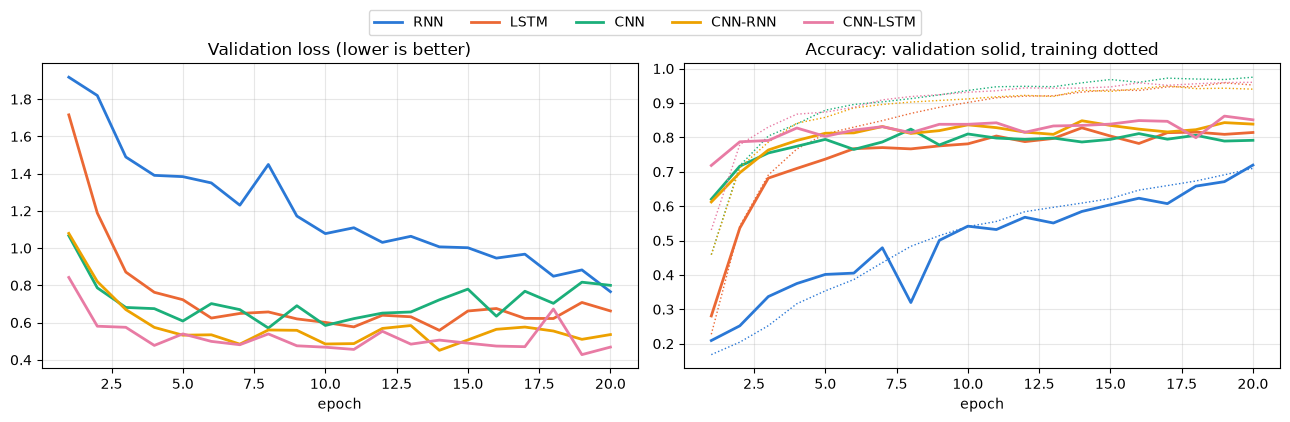

In [ ]:
# One fixed colour per model, used in every chart below
COLOURS = {"RNN": "#2a78d6", "LSTM": "#eb6834",
           "CNN": "#1baf7a", "CNN-RNN": "#eda100",
           "CNN-LSTM": "#e87ba4"}

epochs = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, history in histories.items():
    ax[0].plot(epochs, history["val_loss"], color=COLOURS[name], linewidth=2, label=name)
    ax[1].plot(epochs, history["val_acc"], color=COLOURS[name], linewidth=2, label=name)
    ax[1].plot(epochs, history["train_acc"], color=COLOURS[name], linewidth=1, linestyle=":")
ax[0].set_title("Validation loss (lower is better)")
ax[1].set_title("Accuracy: validation solid, training dotted")
for a in ax:
    a.set_xlabel("epoch")
    a.grid(alpha=0.3)
handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.06))
plt.tight_layout()
plt.show()

## Step 11: test the models

Load each model's best saved version and run it once on the test data, which none of them has seen.

- **Accuracy:** the share of windows a model got right.
- **Macro F1:** the average score across the 6 gestures, each counted equally. It drops if any one gesture is often missed.
- **Model time:** how long one window takes on this computer, one window at a time, as in live use.
- **Total delay:** window length plus model time. The target is under 300 ms.

In [ ]:
def predict(model, loader):
    model.eval()
    predictions = []
    with torch.no_grad():
        for windows, _ in loader:
            predictions.append(model(windows).argmax(dim=1).numpy())
    return np.concatenate(predictions)


def time_one_window_ms(model):
    one_window = torch.tensor(X_test[:1])
    model.eval()
    with torch.no_grad():
        for _ in range(20):                        # warm-up runs
            model(one_window)
        start = time.perf_counter()
        for _ in range(200):
            model(one_window)
    return (time.perf_counter() - start) / 200 * 1000

In [ ]:
models = {}
test_predictions = {}
results = []

for name in MODEL_CLASSES:
    accs, f1s = [], []
    for seed in SEEDS:
        model = build_model(name)
        model.load_state_dict(torch.load(f"best_{name}_seed{seed}.pt"))
        preds = predict(model, test_loader)
        accs.append(accuracy_score(y_test, preds))
        f1s.append(f1_score(y_test, preds, average="macro"))
        if seed == chosen_seed[name]:           # keep one model per type for the later plots and saving
            models[name] = model
            test_predictions[name] = preds

    model_ms = time_one_window_ms(models[name])
    results.append({
        "model": name,
        "accuracy": np.mean(accs),
        "accuracy std": np.std(accs),
        "macro F1": np.mean(f1s),
        "parameters": sum(p.numel() for p in models[name].parameters()),
        "model time (ms)": model_ms,
        "total delay (ms)": WINDOW_MS + model_ms,
        "training time (s)": training_seconds[name],
    })

### Compare with a simple baseline

What each column means

- Accuracy: the share of test windows classified correctly. CNN-LSTM got 95.3% right.
- Macro F1: a score from 0 to 1 that counts all 7 gestures equally. If one gesture is often missed, this drops even when overall accuracy looks fine. When it’s close to accuracy, as it is here, no single gesture is being badly neglected.
- Parameters: how many numbers the model learns, which is a rough measure of its size.
- Model time (ms): how long the model takes to classify one window on your computer. All five are under about 2 ms, which is negligible.
- Total delay (ms): window length plus model time, so roughly 1,000 ms for every model.
training time (s): how long training took. All are under a minute.



In [ ]:
def hand_made_features(windows):
    """4 classic features per channel -> 32 numbers per window."""
    rms = np.sqrt(np.mean(windows ** 2, axis=1))                     # signal strength
    mav = np.mean(np.abs(windows), axis=1)                           # average size
    wl = np.sum(np.abs(np.diff(windows, axis=1)), axis=1)            # how much it wiggles
    zc = np.sum(np.diff(np.sign(windows), axis=1) != 0, axis=1)      # zero crossings
    return np.concatenate([rms, mav, wl, zc], axis=1)


lda = LinearDiscriminantAnalysis()
lda.fit(hand_made_features(X_train), y_train)
lda_predictions = lda.predict(hand_made_features(X_test))

results_table = pd.DataFrame(results).set_index("model")
results_table.loc["LDA baseline", "accuracy"] = accuracy_score(y_test, lda_predictions)
results_table.loc["LDA baseline", "macro F1"] = f1_score(y_test, lda_predictions, average="macro")

results_table.style.format({
    "accuracy": "{:.1%}",
    "accuracy std": "{:.1%}",
    "macro F1": "{:.3f}",
    "parameters": "{:,.0f}",
    "model time (ms)": "{:.2f}",
    "total delay (ms)": "{:.0f}",
    "training time (s)": "{:.0f}",
}, na_rep="-")

,accuracy,accuracy std,macro F1,parameters,model time (ms),total delay (ms),training time (s)
model,,,,,,,
RNN,67.6%,0.8%,0.639,"5,191",0.72,301,13
LSTM,81.2%,1.3%,0.787,"19,399",0.68,301,16
CNN,82.4%,0.6%,0.796,"38,151",2.39,302,31
CNN-RNN,83.9%,0.5%,0.816,"20,583",0.70,301,19
CNN-LSTM,84.8%,0.9%,0.826,"45,543",1.16,301,19
LDA baseline,68.2%,-,0.668,-,-,-,-


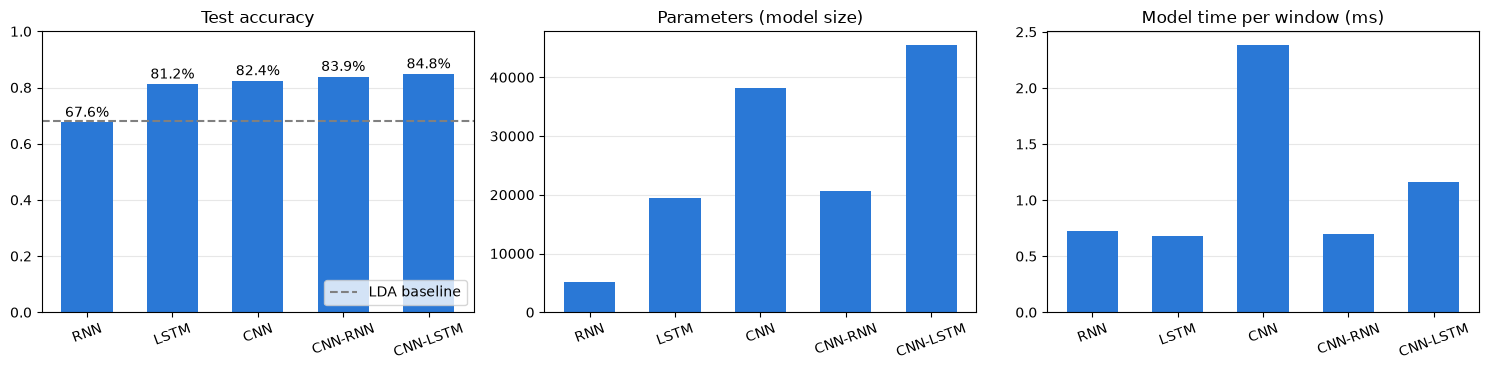

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
names = list(MODEL_CLASSES)

ax[0].bar(names, results_table.loc[names, "accuracy"], color="#2a78d6", width=0.6)
ax[0].axhline(results_table.loc["LDA baseline", "accuracy"], color="grey", linestyle="--", label="LDA baseline")
ax[0].set_ylim(0, 1); ax[0].set_title("Test accuracy"); ax[0].legend(loc="lower right")
for i, value in enumerate(results_table.loc[names, "accuracy"]):
    ax[0].text(i, value + 0.02, f"{value:.1%}", ha="center")

ax[1].bar(names, results_table.loc[names, "parameters"], color="#2a78d6", width=0.6)
ax[1].set_title("Parameters (model size)")

ax[2].bar(names, results_table.loc[names, "model time (ms)"], color="#2a78d6", width=0.6)
ax[2].set_title("Model time per window (ms)")

for a in ax:
    a.tick_params(axis="x", rotation=20)
    a.grid(axis="y", alpha=0.3)
    a.set_axisbelow(True)
plt.tight_layout()
plt.show()

### Confusion matrices

Rows are the true gesture, columns are the model's guess. Numbers off the diagonal are mix-ups. Look for pairs of gestures that several models confuse.

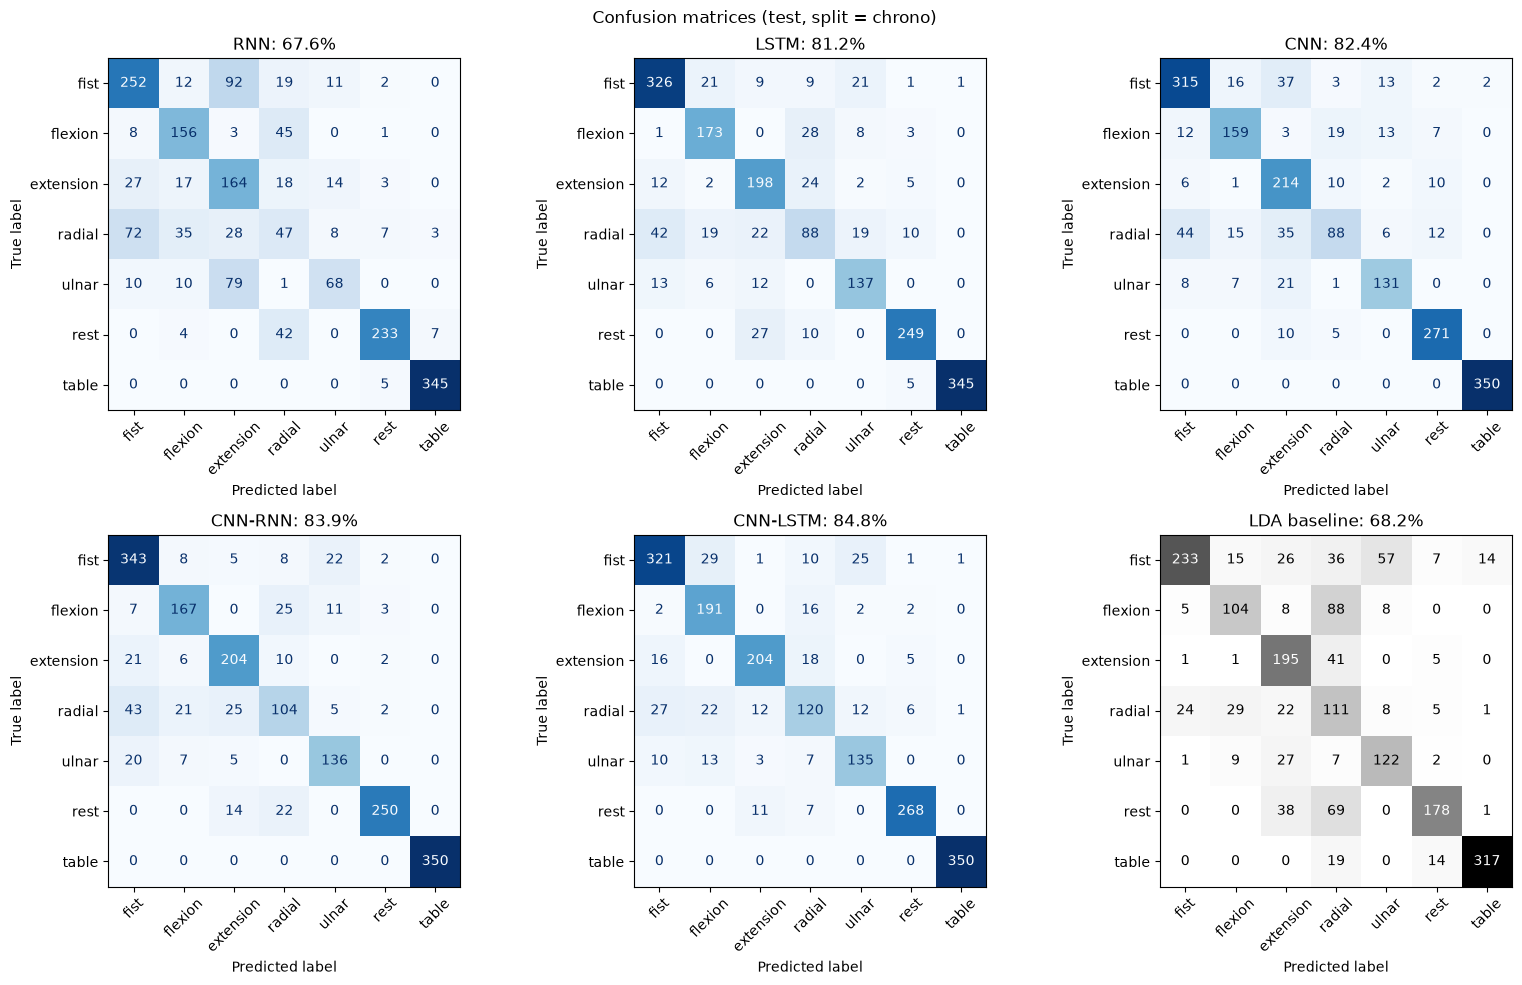

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
for i, name in enumerate(MODEL_CLASSES):
    ConfusionMatrixDisplay.from_predictions(y_test, test_predictions[name], display_labels=GESTURE_NAMES,
                                            xticks_rotation=45, cmap="Blues", colorbar=False, ax=axes[i])
    axes[i].set_title(f"{name}: {results_table.loc[name, 'accuracy']:.1%}")
ConfusionMatrixDisplay.from_predictions(y_test, lda_predictions, display_labels=GESTURE_NAMES,
                                        xticks_rotation=45, cmap="Greys", colorbar=False, ax=axes[5])
axes[5].set_title(f"LDA baseline: {results_table.loc['LDA baseline', 'accuracy']:.1%}")
plt.suptitle(f"Confusion matrices (test, split = {SPLIT_BY})")
plt.tight_layout()
plt.show()

### Accuracy per gesture recording

Each file is one gesture, so this is accuracy on the held-out tail of each recording. A file
that every model struggles with usually means that recording had a problem — a loose band or
a weak contraction — rather than the gesture being intrinsically hard.

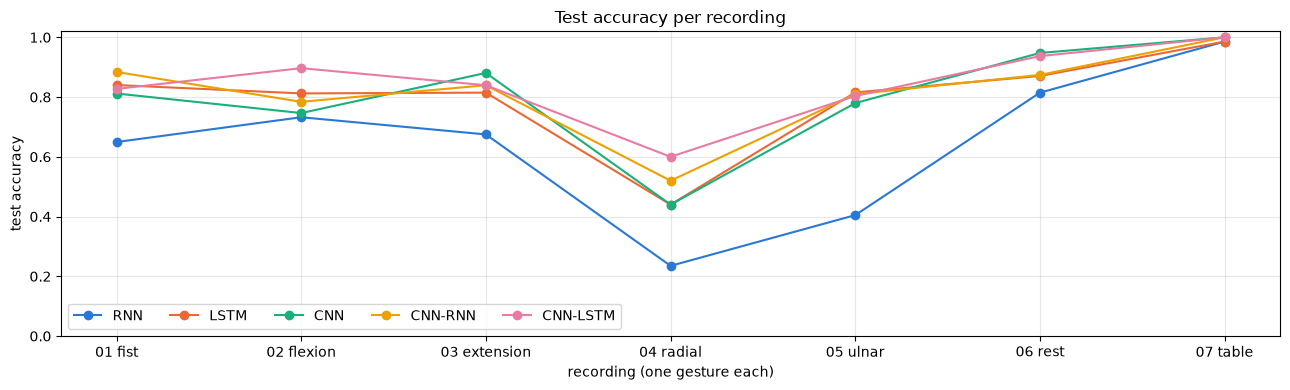

,,RNN,LSTM,CNN,CNN-RNN,CNN-LSTM
recording,gesture,,,,,
01,fist,64.9%,84.0%,81.2%,88.4%,82.7%
02,flexion,73.2%,81.2%,74.6%,78.4%,89.7%
03,extension,67.5%,81.5%,88.1%,84.0%,84.0%
04,radial,23.5%,44.0%,44.0%,52.0%,60.0%
05,ulnar,40.5%,81.5%,78.0%,81.0%,80.4%
06,rest,81.5%,87.1%,94.8%,87.4%,93.7%
07,table,98.6%,98.6%,100.0%,100.0%,100.0%


In [ ]:
per_file = pd.DataFrame({"recording": test_file,
                         "gesture": np.array(GESTURE_NAMES)[y_test]})   # each file holds one gesture
for name in MODEL_CLASSES:
    per_file[name] = test_predictions[name] == y_test
per_file = per_file.groupby(["recording", "gesture"]).mean()

labels = [f"{rec} {gesture}" for rec, gesture in per_file.index]      # e.g. "04 radial"

plt.figure(figsize=(13, 4))
for name in MODEL_CLASSES:
    plt.plot(labels, per_file[name], marker="o", markersize=6,
             color=COLOURS[name], linewidth=1.5, label=name)
plt.ylim(0, 1.02); plt.ylabel("test accuracy"); plt.xlabel("recording (one gesture each)")
plt.title("Test accuracy per recording")
plt.grid(alpha=0.3); plt.legend(ncol=5, loc="lower left")
plt.tight_layout(); plt.show()

per_file.style.format("{:.1%}").background_gradient(cmap="Blues", vmin=0.3, vmax=1.0)

### Detailed report for the best model

Precision: when the model says "fist", how often is it right? Recall: of all the real fists, how many did it catch?

In [ ]:
best_name = results_table.loc[names, "accuracy"].idxmax()
print(f"Best model on the test set: {best_name}\n")
print(classification_report(y_test, test_predictions[best_name], target_names=GESTURE_NAMES, digits=3))

Best model on the test set: CNN-LSTM

              precision    recall  f1-score   support

        fist      0.854     0.827     0.840       388
     flexion      0.749     0.897     0.816       213
   extension      0.883     0.840     0.861       243
      radial      0.674     0.600     0.635       200
       ulnar      0.776     0.804     0.789       168
        rest      0.950     0.937     0.944       286
       table      0.994     1.000     0.997       350

    accuracy                          0.860      1848
   macro avg      0.840     0.843     0.840      1848
weighted avg      0.861     0.860     0.859      1848



## Step 12: save everything needed to use the models later

The weights alone are not enough. Live data must go through exactly the same filters, window size and normalisation, so those settings are saved in the same file as each model, for example `CNN-LSTM_semg.pt`.

In [ ]:
for name, model in models.items():
    torch.save({
        "model_name": name,
        "model_weights": model.state_dict(),
        "channel_mean": channel_mean.tolist(),     # plain lists, so torch.load works without extra flags
        "channel_std": channel_std.tolist(),
        "sample_rate": SAMPLE_RATE,
        "window_size": WINDOW_SIZE,
        "notch_hz": NOTCH_HZ,
        "bandpass_hz": (LOW_HZ, HIGH_HZ),
        "gestures": GESTURE_NAMES,
        "split": SPLIT_BY,
        "test_accuracy": float(results_table.loc[name, "accuracy"]),
        "test_macro_f1": float(results_table.loc[name, "macro F1"]),
    }, f"{name}_semg.pt")
    print(f"saved {name}_semg.pt")

saved RNN_semg.pt
saved LSTM_semg.pt
saved CNN_semg.pt
saved CNN-RNN_semg.pt
saved CNN-LSTM_semg.pt


### How much of this is temporal, and how much is just amplitude?

The sequence models only earn their place if they beat a classifier that cannot see time at
all. This fits an LDA to the per-channel RMS of each window — eight numbers, every trace of
temporal structure discarded — and to a single sample per window.

If the RMS score lands close to your best deep model, the task is being solved by "how hard
is each electrode reading", not by how the signal evolves, and the recurrent layers are
decoration. That is the expected result when every gesture is one long steady hold: there
are no onsets or transitions in the data for a sequence model to work with.

In [ ]:
rms_of = lambda W: np.sqrt(np.mean(W ** 2, axis=1))          # [windows, 8]
mid_of = lambda W: W[:, W.shape[1] // 2, :]                   # one sample, [windows, 8]

for label, f in (("per-channel RMS (8 numbers, no temporal info)", rms_of),
                 ("one sample per window (8 numbers)", mid_of)):
    model = LinearDiscriminantAnalysis().fit(f(X_train), y_train)
    score = accuracy_score(y_test, model.predict(f(X_test)))
    print(f"LDA on {label:48s} {score:6.1%}")

best = results_table.loc[list(MODEL_CLASSES), "accuracy"].max()
print(f"\nbest deep model{'':40s} {best:6.1%}")
print(f"LDA on 32 hand-made features{'':27s} "
      f"{results_table.loc['LDA baseline', 'accuracy']:6.1%}")

LDA on per-channel RMS (8 numbers, no temporal info)     61.1%
LDA on one sample per window (8 numbers)                 18.2%

best deep model                                          84.8%
LDA on 32 hand-made features                             68.2%


## Notes and next steps

- **Try the other split.** Set `SPLIT = "subject"` in Step 1 and run everything again. The gap between the two scores shows how much each model depends on knowing the person.
- **One run is one sample.** Results move by a percent or two with a different `SEED`. Before declaring a winner, run two or three seeds and compare the averages.
- **Zero-centering here uses each whole recording's average.** A live system can't know that in advance. It would use a short calibration recording instead. The band-pass filter also removes any leftover offset, so the effect is small.
- **Live filtering keeps memory between chunks.** Here each recording is filtered in one go. Live, the signal arrives in pieces, so the filter's memory (`zi` in `sosfilt`/`lfilter`) has to be carried from one chunk to the next.
- **Ideas to try, one at a time:** `WINDOW_MS = 200`; more or fewer filters; `hidden_size=32`; more epochs; more dropout to reduce overfitting.
